<a href="https://colab.research.google.com/github/Git76Hub/IoT-Bases-Smart-Home-System/blob/main/Machine_Learning_Laboratory_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [34]:


rng = np.random.default_rng(7)


n = 80
d = 40

X = rng.standard_normal((n, d))


epsilon = rng.normal(0, 2, n)


y = (1
     + 3 * X[:, 0]
     - 2 * X[:, 1]
     + 1.5 * X[:, 2]
     + 0.5 * X[:, 3]
     - X[:, 4]
     + epsilon)

print("Dataset generated successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)


Dataset generated successfully!
X shape: (80, 40)
y shape: (80,)


In [35]:


indices = rng.permutation(n)


train_indices = indices[:56]


test_indices = indices[56:]


X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]


print("Training and Testing Dimensions")
print("--------------------------------")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


Training and Testing Dimensions
--------------------------------
X_train: (56, 40)
X_test: (24, 40)
y_train: (56,)
y_test: (24,)


In [8]:

def calculate_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

print("MSE function created successfully!")


MSE function created successfully!


In [36]:


X_train_5 = X_train[:, :5]
X_test_5 = X_test[:, :5]


X_train_5_bias = np.column_stack(
    (np.ones(X_train_5.shape[0]), X_train_5)
)

X_test_5_bias = np.column_stack(
    (np.ones(X_test_5.shape[0]), X_test_5)
)

print("Training matrix:", X_train_5_bias.shape)
print("Testing matrix:", X_test_5_bias.shape)


Training matrix: (56, 6)
Testing matrix: (24, 6)


In [37]:


A = X_train_5_bias.T @ X_train_5_bias
b = X_train_5_bias.T @ y_train


theta_5 = np.linalg.solve(A, b)


bias_5 = theta_5[0]
weights_5 = theta_5[1:]

print("Estimated Bias:", bias_5)
print("\nEstimated Weights:")
for i, weight in enumerate(weights_5, start=1):
    print(f"Weight {i}: {weight}")


Estimated Bias: 0.9893935789904259

Estimated Weights:
Weight 1: 2.859685609857432
Weight 2: -2.5897001711453815
Weight 3: 1.64618567770527
Weight 4: -0.01447182630443316
Weight 5: -1.3410742687864095


In [38]:

y_train_pred_5 = X_train_5_bias @ theta_5
y_test_pred_5 = X_test_5_bias @ theta_5

train_mse_5 = calculate_mse(y_train, y_train_pred_5)
test_mse_5 = calculate_mse(y_test, y_test_pred_5)

print("Task 2 Results")
print("------------------------")
print("Training MSE:", train_mse_5)
print("Testing MSE:", test_mse_5)


Task 2 Results
------------------------
Training MSE: 3.554275072567624
Testing MSE: 4.462737613078482


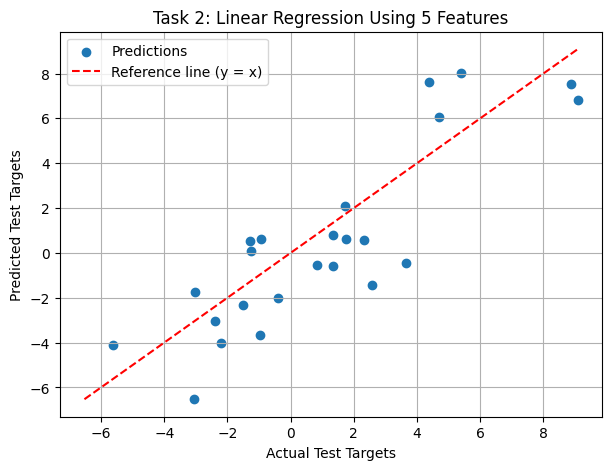

In [39]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_test_pred_5, label="Predictions")

minimum = min(y_test.min(), y_test_pred_5.min())
maximum = max(y_test.max(), y_test_pred_5.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label="Reference line (y = x)"
)

plt.xlabel("Actual Test Targets")
plt.ylabel("Predicted Test Targets")
plt.title("Task 2: Linear Regression Using 5 Features")
plt.legend()
plt.grid(True)
plt.show()


In [40]:


X_train_40 = np.column_stack(
    (np.ones(X_train.shape[0]), X_train)
)

X_test_40 = np.column_stack(
    (np.ones(X_test.shape[0]), X_test)
)

print("Training matrix:", X_train_40.shape)
print("Testing matrix:", X_test_40.shape)


Training matrix: (56, 41)
Testing matrix: (24, 41)


In [41]:

A_40 = X_train_40.T @ X_train_40
b_40 = X_train_40.T @ y_train

theta_40 = np.linalg.solve(A_40, b_40)

print("Number of parameters:", len(theta_40))
print("\nEstimated parameters:")
print(theta_40)


Number of parameters: 41

Estimated parameters:
[ 8.18022864e-01  2.60201193e+00 -2.62625796e+00  1.40172896e+00
  1.77086083e-01 -1.10620373e+00 -1.05259113e+00  1.03425077e-02
  5.94873367e-01  4.96881279e-01  5.22677477e-01  4.48243933e-01
  6.98896068e-01 -9.42249916e-03 -2.44495777e-01 -2.40410962e-01
  6.37274434e-01 -1.89039726e-02  1.71333941e-01 -1.85344699e-04
  5.99801905e-02  4.45739339e-01  4.64502484e-01  2.83244915e-01
  4.93902084e-01  2.58926253e-01  1.52121800e-01  6.22084382e-01
 -4.96872296e-01 -1.07980789e-01 -2.28953976e-01  1.88330427e-01
 -1.97679197e-02 -6.40234321e-01 -2.09784924e-01 -1.16427747e-01
  2.89394902e-01 -3.43647064e-01  5.30546665e-01  1.31186577e+00
 -3.34259723e-01]


In [42]:

y_train_pred_40 = X_train_40 @ theta_40
y_test_pred_40 = X_test_40 @ theta_40

train_mse_40 = calculate_mse(y_train, y_train_pred_40)
test_mse_40 = calculate_mse(y_test, y_test_pred_40)

theta_norm_40 = np.linalg.norm(theta_40)

print("Task 3 Results")
print("------------------------")
print("Training MSE:", train_mse_40)
print("Testing MSE:", test_mse_40)
print("Parameter Norm:", theta_norm_40)


Task 3 Results
------------------------
Training MSE: 0.6665734191850946
Testing MSE: 13.558911420889643
Parameter Norm: 5.013117624091856


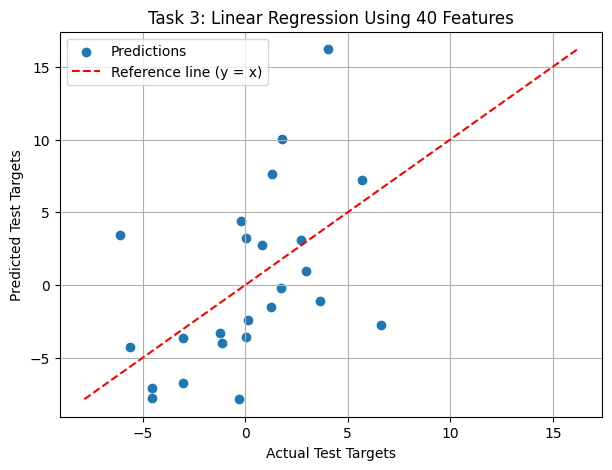

In [24]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_test_pred_40, label="Predictions")

minimum = min(y_test.min(), y_test_pred_40.min())
maximum = max(y_test.max(), y_test_pred_40.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label="Reference line (y = x)"
)

plt.xlabel("Actual Test Targets")
plt.ylabel("Predicted Test Targets")
plt.title("Task 3: Linear Regression Using 40 Features")
plt.legend()
plt.grid(True)
plt.show()


In [26]:

print("Comparison: Task 2 vs Task 3")
print("-----------------------------------")

print(f"{'Metric':<20} {'5 Features':<15} {'40 Features'}")
print("-" * 50)

print(f"{'Training MSE':<20} {train_mse_5:<15.4f} {train_mse_40:.4f}")
print(f"{'Testing MSE':<20} {test_mse_5:<15.4f} {test_mse_40:.4f}")
print(f"{'Parameter Norm':<20} {np.linalg.norm(theta_5):<15.4f} {theta_norm_40:.4f}")


Comparison: Task 2 vs Task 3
-----------------------------------
Metric               5 Features      40 Features
--------------------------------------------------
Training MSE         4.1265          0.6936
Testing MSE          2.4384          26.2959
Parameter Norm       4.1411          5.9791


In [43]:

lambdas = [0.01, 0.1, 10]

n_train = X_train_40.shape[0]

I = np.eye(X_train_40.shape[1])

ridge_results = {}

for lam in lambdas:

    A_ridge = (X_train_40.T @ X_train_40) + (n_train * lam * I)

    b_ridge = X_train_40.T @ y_train

    theta_ridge = np.linalg.solve(A_ridge, b_ridge)

    y_train_pred = X_train_40 @ theta_ridge
    y_test_pred = X_test_40 @ theta_ridge

    train_mse = calculate_mse(y_train, y_train_pred)
    test_mse = calculate_mse(y_test, y_test_pred)

    parameter_norm = np.linalg.norm(theta_ridge)

    ridge_results[lam] = {
        "theta": theta_ridge,
        "train_mse": train_mse,
        "test_mse": test_mse,
        "norm": parameter_norm
    }

print("Ridge Regression completed successfully!")


Ridge Regression completed successfully!


In [30]:

print("RIDGE REGRESSION RESULTS")
print("=" * 75)

print(f"{'Lambda':<12} {'Training MSE':<18} {'Testing MSE':<18} {'Parameter Norm'}")
print("-" * 75)

for lam, result in ridge_results.items():

    print(
        f"{lam:<12} "
        f"{result['train_mse']:<18.4f} "
        f"{result['test_mse']:<18.4f} "
        f"{result['norm']:.4f}"
    )


RIDGE REGRESSION RESULTS
Lambda       Training MSE       Testing MSE        Parameter Norm
---------------------------------------------------------------------------
0.01         0.7213             19.3659            5.4512
0.1          1.3496             6.9416             3.7843
10           12.6577            9.9457             0.3796


In [32]:

print("TEST MSE COMPARISON")
print("=" * 50)

print(f"Linear Regression (5 features):  {test_mse_5:.4f}")
print(f"Linear Regression (40 features): {test_mse_40:.4f}")

for lam, result in ridge_results.items():
    print(f"Ridge Regression (lambda={lam}): {result['test_mse']:.4f}")


TEST MSE COMPARISON
Linear Regression (5 features):  2.4384
Linear Regression (40 features): 26.2959
Ridge Regression (lambda=0.01): 19.3659
Ridge Regression (lambda=0.1): 6.9416
Ridge Regression (lambda=10): 9.9457


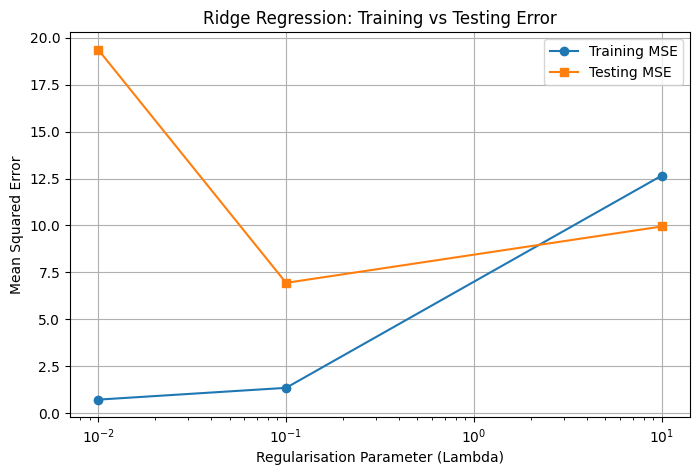

In [33]:

ridge_lambdas = list(ridge_results.keys())

ridge_train_errors = [
    ridge_results[lam]["train_mse"]
    for lam in ridge_lambdas
]

ridge_test_errors = [
    ridge_results[lam]["test_mse"]
    for lam in ridge_lambdas
]

plt.figure(figsize=(8, 5))

plt.plot(
    ridge_lambdas,
    ridge_train_errors,
    marker='o',
    label="Training MSE"
)

plt.plot(
    ridge_lambdas,
    ridge_test_errors,
    marker='s',
    label="Testing MSE"
)

plt.xscale("log")
plt.xlabel("Regularisation Parameter (Lambda)")
plt.ylabel("Mean Squared Error")
plt.title("Ridge Regression: Training vs Testing Error")
plt.legend()
plt.grid(True)
plt.show()
